In [182]:
import numpy as pd 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib


In [183]:
df = pd.read_csv("insurance.csv")
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [184]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [185]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

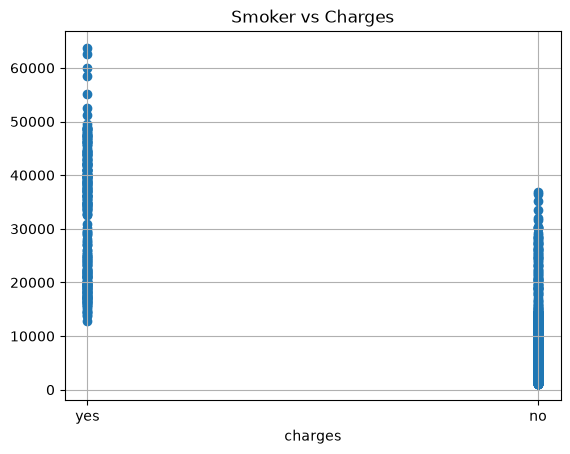

In [186]:
plt.scatter(x = df['smoker'] , y= df['charges'])
plt.xlabel("Smoker")
plt.xlabel("charges")
plt.title("Smoker vs Charges")
plt.grid(True)

Text(0.5, 1.0, 'Age vs Charges')

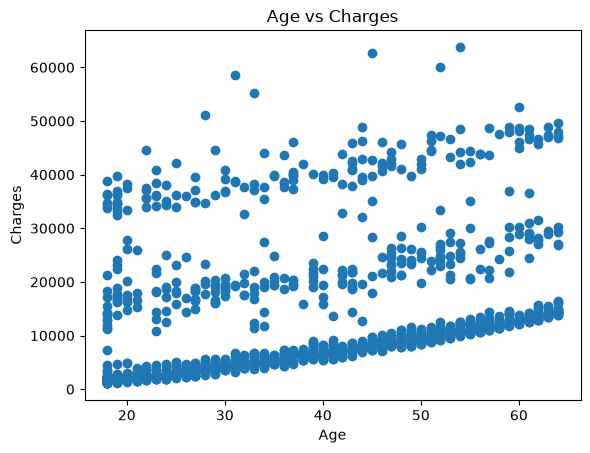

In [187]:
plt.scatter(x= df['age'] , y= df['charges'])
plt.xlabel("Age")
plt.ylabel("Charges")
plt.title("Age vs Charges")

Text(0.5, 1.0, 'Bmi vs Charges')

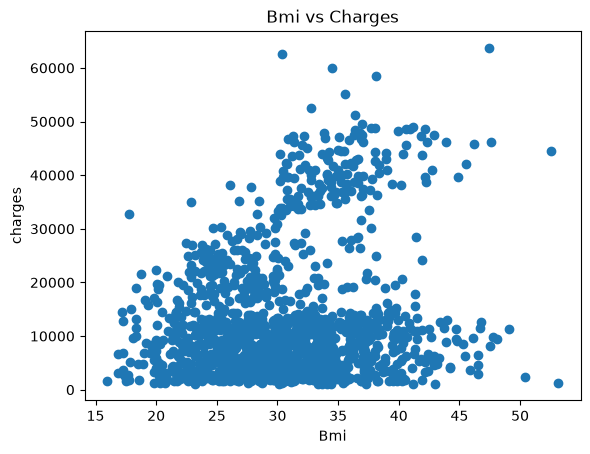

In [188]:
plt.scatter( x= df['bmi'] , y=df['charges'])
plt.xlabel("Bmi")
plt.ylabel('charges')
plt.title("Bmi vs Charges")

Text(0.5, 1.0, 'Age vs Charegs by Smoker')

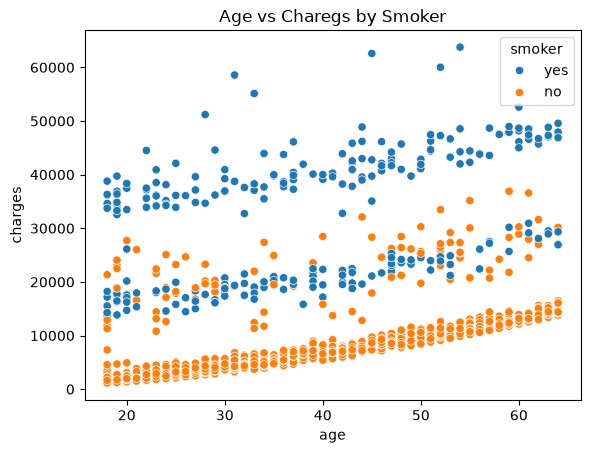

In [189]:
sns.scatterplot(
    data=df,
    x= 'age',
    y = 'charges',
    hue='smoker'
)
plt.title("Age vs Charegs by Smoker")

<Axes: >

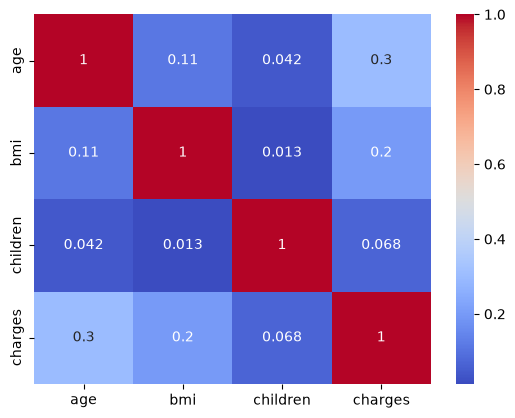

In [190]:
sns.heatmap(
    df[['age' , 'bmi' , 'children' , 'charges']].corr(),
    annot = True,
    cmap="coolwarm"
)

In [191]:
df['sex'] = df['sex'].map({"male" : 1 , "female" : 0})
df['smoker']=df['smoker'].map({"yes" : 1 , "no" : 0})
df

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,southwest,16884.92400
1,18,1,33.770,1,0,southeast,1725.55230
2,28,1,33.000,3,0,southeast,4449.46200
3,33,1,22.705,0,0,northwest,21984.47061
4,32,1,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,northwest,10600.54830
1334,18,0,31.920,0,0,northeast,2205.98080
1335,18,0,36.850,0,0,southeast,1629.83350
1336,21,0,25.800,0,0,southwest,2007.94500


In [192]:
df['region'] = df['region'].map({
    "southwest" : 0,
    "northwest" : 1,
    "southeast" : 2,
    "northeast" : 3,
})
df

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,0,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520
...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,1,10600.54830
1334,18,0,31.920,0,0,3,2205.98080
1335,18,0,36.850,0,0,2,1629.83350
1336,21,0,25.800,0,0,0,2007.94500


In [193]:
x  = df.drop('charges' , axis=1 )
x

,age,sex,bmi,children,smoker,region
0,19,0,27.900,0,1,0
1,18,1,33.770,1,0,2
2,28,1,33.000,3,0,2
3,33,1,22.705,0,0,1
4,32,1,28.880,0,0,1
...,...,...,...,...,...,...
1333,50,1,30.970,3,0,1
1334,18,0,31.920,0,0,3
1335,18,0,36.850,0,0,2
1336,21,0,25.800,0,0,0


In [194]:
y = df['charges']
y

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1338, dtype: float64

In [195]:
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [196]:
from sklearn.model_selection import train_test_split


In [197]:
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size=0.2 , random_state=42)

In [198]:
x_train

,age,sex,bmi,children,smoker,region
560,46,0,19.950,2,0,1
1285,47,0,24.320,0,0,3
1142,52,0,24.860,0,0,2
969,39,0,34.320,5,0,2
486,54,0,21.470,3,0,1
...,...,...,...,...,...,...
1095,18,0,31.350,4,0,3
1130,39,0,23.870,5,0,2
1294,58,1,25.175,0,0,3
860,37,0,47.600,2,1,0


In [199]:
x_test

,age,sex,bmi,children,smoker,region
764,45,0,25.175,2,0,3
887,36,0,30.020,0,0,1
890,64,0,26.885,0,1,1
1293,46,1,25.745,3,0,1
259,19,1,31.920,0,1,1
...,...,...,...,...,...,...
109,63,1,35.090,0,1,2
575,58,0,27.170,0,0,1
535,38,1,28.025,1,0,3
543,54,0,47.410,0,1,2


In [200]:
y_test

764      9095.06825
887      5272.17580
890     29330.98315
1293     9301.89355
259     33750.29180
           ...     
109     47055.53210
575     12222.89830
535      6067.12675
543     63770.42801
846      9872.70100
Name: charges, Length: 268, dtype: float64

In [201]:
y_train

560      9193.83850
1285     8534.67180
1142    27117.99378
969      8596.82780
486     12475.35130
           ...     
1095     4561.18850
1130     8582.30230
1294    11931.12525
860     46113.51100
1126    10214.63600
Name: charges, Length: 1070, dtype: float64

In [202]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train , y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 257.48, -9.74, 328.34, 429.59,23630.06, 212.62]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.247e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [203]:
y_test

764      9095.06825
887      5272.17580
890     29330.98315
1293     9301.89355
259     33750.29180
           ...     
109     47055.53210
575     12222.89830
535      6067.12675
543     63770.42801
846      9872.70100
Name: charges, Length: 268, dtype: float64

In [204]:
y_pred = model.predict(x_test)
y_pred

array([ 8.87605306e+03,  6.86511267e+03,  3.66753456e+04,  9.31530243e+03,
        2.67320683e+04,  1.07864065e+04,  2.37035683e+01,  1.66538647e+04,
        1.05070328e+03,  1.10547153e+04,  2.81713973e+04,  9.18911358e+03,
        5.56374780e+03,  3.86100781e+04,  4.04565557e+04,  3.73183330e+04,
        1.54409753e+04,  3.61400195e+04,  9.43531352e+03,  3.12682029e+04,
        3.94892496e+03,  1.01514277e+04,  2.39031505e+03,  6.89840060e+03,
        1.11347834e+04,  1.27984272e+04,  1.45000590e+04,  5.96129206e+03,
        9.85890479e+03,  2.47269747e+03,  9.16436440e+03,  1.28649106e+04,
        4.80793829e+03,  3.30257868e+03,  4.49094513e+03,  1.28107697e+04,
        2.03124245e+03,  8.84506119e+03,  3.31105562e+04,  3.28284397e+04,
        3.95696871e+03,  4.11689043e+03,  1.41295512e+04,  1.12802474e+04,
        9.03610575e+03,  1.21670313e+04,  5.04734969e+03,  3.23082963e+03,
        3.57428142e+04,  9.38795974e+03,  1.60917510e+04,  2.64946055e+03,
        1.20677164e+04,  

In [205]:
from sklearn.metrics import mean_squared_error , r2_score
print("mean squared error : " , mean_squared_error(y_test , y_pred))
print("r2 score : " , r2_score(y_test , y_pred))

mean squared error :  33927609.01712134
r2 score :  0.7814628906071344


In [206]:
comparison = pd.DataFrame({
    'Actual' : y_test,
    "predicted" : y_pred
})
comparison.head(5)

,Actual,predicted
764,9095.06825,8876.053056
887,5272.17580,6865.112675
890,29330.98315,36675.345581
1293,9301.89355,9315.302426
259,33750.29180,26732.068320


<Axes: xlabel='charges'>

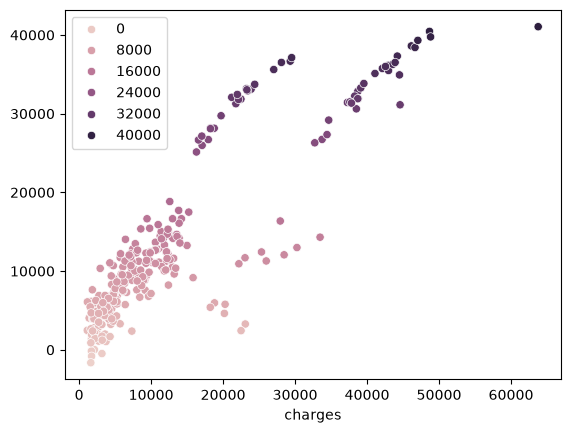

In [207]:
sns.scatterplot(x=y_test , y= y_pred , hue= y_pred)

In [208]:
pip install streamlit pandas scikit-learn joblib


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [209]:


joblib.dump(model, "insurance_model.pkl")
joblib.dump(x_train.columns.tolist(), "columns.pkl")

['columns.pkl']